# Pneumonia Detection using Transfer Learning (InceptionV3)

This notebook demonstrates a deep learning workflow to detect pneumonia from chest X-ray images using **InceptionV3** and **Keras/TensorFlow**. It includes data augmentation, feature extraction, fine-tuning, and model evaluation.

In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt

## 1. Setup and Environment Configuration
Define the dataset paths for training, validation, and testing.

In [ ]:
# Dataset path configuration
# Supports environment variable, local project directory, Kaggle/Colab, or legacy path
import os

candidate_paths = [
    os.environ.get('CHEST_XRAY_DIR', ''),
    os.path.join('data', 'chest_xray'),
    'chest_xray',
    '/kaggle/input/chest-xray-pneumonia/chest_xray',
    r'C:\Users\PC\Desktop\PNEUMONIA Dataset\chest_xray',
]

base_dir = None
for path in candidate_paths:
    if path and os.path.exists(path):
        base_dir = path
        break

if base_dir is None:
    base_dir = os.path.join('data', 'chest_xray')
    print(f'[INFO] Dataset directory configured to default: {base_dir}')
    print('[INFO] Set CHEST_XRAY_DIR or place dataset in ./data/chest_xray to run.')
else:
    print(f'[INFO] Dataset directory found: {base_dir}')

train_dir = os.path.join(base_dir, 'train')
val_dir   = os.path.join(base_dir, 'val')
test_dir  = os.path.join(base_dir, 'test')


## 2. Data Preparation and Augmentation
We apply data augmentation techniques to the training set to prevent overfitting, and scale all pixel values to the range $[0, 1]$.

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)
test_val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='binary',
    shuffle=True
)

val_gen = test_val_datagen.flow_from_directory(
    val_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_gen = test_val_datagen.flow_from_directory(
    test_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


Found 4446 images belonging to 2 classes.
Found 786 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


## 3. Model Architecture
We load the **InceptionV3** base model pretrained on ImageNet, append a global average pooling layer, a fully connected layer, and a sigmoid classification layer. We freeze the base model layers for initial training.

In [ ]:
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(1, activation='sigmoid')(x)
model = Model(inputs=base_model.input, outputs=predictions)

# Freeze base model
for layer in base_model.layers:
    layer.trainable = False

### Compile the Model (Initial Phase)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

### Callbacks Setup

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint  = ModelCheckpoint("best_model.h5", monitor='val_loss', save_best_only=True)

## 4. Phase 1 Training (Feature Extraction)
Train only the top classification layers.

In [ ]:
history = model.fit(
    train_gen,
    epochs=20,
    validation_data=val_gen,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

C:\Users\PC\anaconda3\Nouveaud\envs\ML\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8109 - loss: 0.6424   

139/139 ━━━━━━━━━━━━━━━━━━━━ 985s 7s/step - accuracy: 0.8114 - loss: 0.6401 - val_accuracy: 0.7926 - val_loss: 0.4401
Epoch 2/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9271 - loss: 0.1911   

139/139 ━━━━━━━━━━━━━━━━━━━━ 1435s 10s/step - accuracy: 0.9272 - loss: 0.1910 - val_accuracy: 0.9211 - val_loss: 0.2024
Epoch 3/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 1105s 8s/step - accuracy: 0.9372 - loss: 0.1526 - val_accuracy: 0.9122 - val_loss: 0.2198
Epoch 4/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 660s 5s/step - accuracy: 0.9435 - loss: 0.1453 - val_accuracy: 0.9097 - val_loss: 0.2212
Epoch 5/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9425 - loss: 0.1496  

139/139 ━━━━━━━━━━━━━━━━━━━━ 591s 4s/step - accuracy: 0.9425 - loss: 0.1496 - val_accuracy: 0.9338 - val_loss: 0.1755
Epoch 6/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 622s 4s/step - accuracy: 0.9503 - loss: 0.1256 - val_accuracy: 0.8855 - val_loss: 0.2750
Epoch 7/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 626s 5s/step - accuracy: 0.9462 - loss: 0.1369 - val_accuracy: 0.9262 - val_loss: 0.1853
Epoch 8/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9536 - loss: 0.1299  

139/139 ━━━━━━━━━━━━━━━━━━━━ 676s 5s/step - accuracy: 0.9537 - loss: 0.1298 - val_accuracy: 0.9466 - val_loss: 0.1386
Epoch 9/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 706s 5s/step - accuracy: 0.9456 - loss: 0.1324 - val_accuracy: 0.9160 - val_loss: 0.2291
Epoch 10/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 639s 5s/step - accuracy: 0.9614 - loss: 0.1059 - val_accuracy: 0.8193 - val_loss: 0.4706
Epoch 11/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 674s 5s/step - accuracy: 0.9483 - loss: 0.1357 - val_accuracy: 0.9389 - val_loss: 0.1562
Epoch 12/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 707s 5s/step - accuracy: 0.9535 - loss: 0.1179 - val_accuracy: 0.9351 - val_loss: 0.2000
Epoch 13/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 686s 5s/step - accuracy: 0.9495 - loss: 0.1281 - val_accuracy: 0.8690 - val_loss: 0.3321


## 5. Phase 2 Training (Fine-Tuning)
Unfreeze the top 100 layers of the base model and train with a very low learning rate to fine-tune the weights.

In [ ]:
for layer in base_model.layers[-100:]:
    layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
fine_tune_history = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_gen,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 800s 5s/step - accuracy: 0.9371 - loss: 0.1708 - val_accuracy: 0.9148 - val_loss: 0.2229
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 765s 5s/step - accuracy: 0.9539 - loss: 0.1209 - val_accuracy: 0.9338 - val_loss: 0.1775
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 705s 5s/step - accuracy: 0.9645 - loss: 0.0943 - val_accuracy: 0.9224 - val_loss: 0.2058
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 774s 6s/step - accuracy: 0.9714 - loss: 0.0727 - val_accuracy: 0.9338 - val_loss: 0.1767
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 784s 6s/step - accuracy: 0.9662 - loss: 0.0772 - val_accuracy: 0.9249 - val_loss: 0.2051
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 790s 6s/step - accuracy: 0.9781 - loss: 0.0651 - val_accuracy: 0.9338 - val_loss: 0.1628
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 781s 6s/step - accuracy: 0.9778 - loss: 0.0644 - val_accuracy: 0.9300 - val_loss: 0.1744
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 821s 6s/step - accuracy: 0.9772 - loss: 0.0699 - val_accu

139/139 ━━━━━━━━━━━━━━━━━━━━ 861s 6s/step - accuracy: 0.9815 - loss: 0.0558 - val_accuracy: 0.9491 - val_loss: 0.1277


## 6. Model Evaluation
Evaluate the performance of our fine-tuned model on the unseen test set.

In [ ]:
test_loss, test_acc = model.evaluate(test_gen, verbose=1)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f} ({test_acc*100:.2f} %)")

20/20 ━━━━━━━━━━━━━━━━━━━━ 68s 3s/step - accuracy: 0.8766 - loss: 0.3813 
Test loss: 0.2490, Test accuracy: 0.9183 (91.83 %)


### Plotting Training Curves

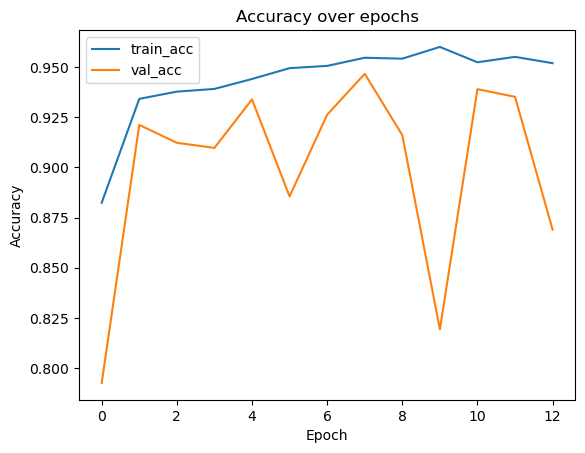

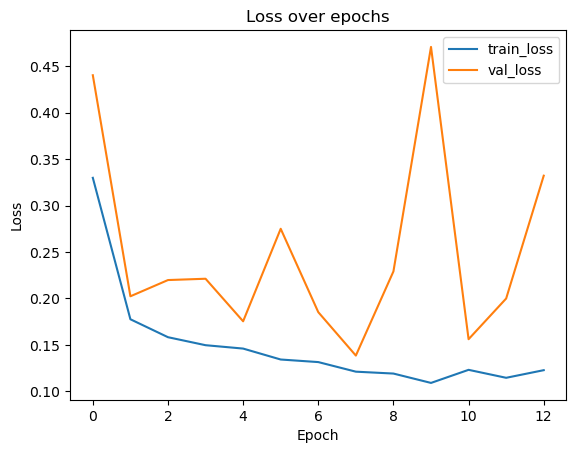

In [ ]:
plt.figure()
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.title('Accuracy over epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.figure()
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Loss over epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## 7. Performance Metrics
Predict the classes of the test set and analyze the confusion matrix and classification report.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
# Get true labels
y_true = test_gen.classes

# Predict probabilities
y_pred_probs = model.predict(test_gen, verbose=1)

# Convert probabilities to class labels (0 or 1)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()


20/20 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step 


### Confusion Matrix

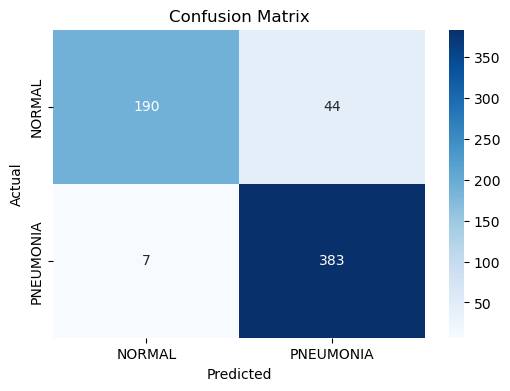

In [ ]:
cm = confusion_matrix(y_true, y_pred)

class_names = list(test_gen.class_indices.keys())

# Plot it
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


### Classification Report

In [ ]:
print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

      NORMAL       0.96      0.81      0.88       234
   PNEUMONIA       0.90      0.98      0.94       390

    accuracy                           0.92       624
   macro avg       0.93      0.90      0.91       624
weighted avg       0.92      0.92      0.92       624



## 8. Save the Final Model

In [ ]:
model.save("my_model.keras")

## 9. Summary & Key Results

### Model Performance on Test Set
- **Test Accuracy**: `91.83%`
- **Recall for Pneumonia (True Positive Rate)**: `98%`
- **Precision for Pneumonia**: `90%`

### Key Takeaway
In medical imaging, having a high recall for the positive class (Pneumonia) is crucial, as we want to minimize false negatives (failing to detect pneumonia when it is present). Our model achieved an outstanding **98% recall**, making it highly effective at screening chest X-rays.

### How to Load and Use the Saved Model
You can quickly reload the saved `.keras` model using the following code snippet:

In [1]:
# Example of how to load the model in a new session
# from tensorflow.keras.models import load_model
# loaded_model = load_model('my_model.keras')
# print("Model loaded successfully!")